# Capítulo 5 · Actividad: Titanic, ¿árbol o vecinos?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/04_actividad_titanic_arbol_knn.ipynb)

Compara un **árbol de decisión** y **KNN** para predecir si un pasajero del Titanic sobrevivió. Primero entiende los datos; el preprocesamiento lo decides tú. Los dos modelos tienen que evaluarse sobre la misma división de train y test, y con las mismas particiones de validación cruzada.

Cada fila es un pasajero. Para esta actividad usa las siguientes variables:

| Variable | Significado |
|---|---|
| `survived` | **Target**: `0` = no sobrevivió, `1` = sobrevivió |
| `pclass` | Clase del boleto: primera, segunda o tercera |
| `sex` | Sexo del pasajero |
| `age` | Edad en años |
| `sibsp` | Número de hermanos y cónyuges a bordo |
| `parch` | Número de padres e hijos a bordo |
| `fare` | Tarifa pagada |
| `embarked` | Puerto de embarque: `C`, `Q` o `S` |

Hay valores faltantes en `age` y `embarked`. Las clases de supervivencia no están balanceadas y las variables numéricas tienen escalas distintas.

**Usa únicamente las siete variables predictoras de la tabla.** El CSV contiene otras columnas: `alive`, por ejemplo, expresa la misma respuesta que `survived`. Incluirla entre las entradas sería una fuga de información: el modelo recibiría la respuesta que debe predecir. Tampoco incluyas `survived` entre las entradas.

Como mínimo, tu notebook debe incluir:

- La exploración de antes de modelar: forma de la tabla, nulos, balance de supervivencia, distribuciones y relación de las variables con la supervivencia.
- Una división estratificada de train y test y validación cruzada estratificada sobre train. Usa `random_state=42` en la división, en el árbol y al mezclar las particiones de validación.
- Un **árbol de decisión** y un **KNN**, los dos para clasificar. Decide cómo tratar los nulos, cómo codificar las variables categóricas y si estandarizas las numéricas: a KNN la escala le importa, al árbol no. Integra el preprocesamiento en un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada partición.
- La profundidad del árbol (y `min_samples_leaf`, si quieres) elegida con `GridSearchCV` sobre la validación cruzada.
- Para KNN, varios valores de `k`, incluyendo `k=1`, una **gráfica de la accuracy de train y de validación contra `k`** y el `k` que alcanza el máximo en validación. Distingue la accuracy sobre los mismos datos usados para entrenar de la obtenida en las particiones de validación. El test se usa una vez, al final, para evaluar ambos modelos elegidos, no para escoger hiperparámetros.
- Una **tabla** con los dos modelos: accuracy en validación cruzada (media y desviación estándar) y en prueba, y la matriz de confusión de cada uno en prueba. Compara también con una referencia sencilla: predecir siempre la clase mayoritaria de train.
- Tus **conclusiones**: con cuál te quedas y por qué. Explica la diferencia entre train y validación con `k=1`, cómo cambia al aumentar `k` y qué errores comete cada modelo al predecir supervivencia.

No hay una accuracy objetivo ni un ganador obligatorio. El objetivo es justificar la comparación con los resultados: `k=1` puede generalizar bien y la curva de validación no tiene por qué mejorar siempre al aumentar `k`. Si los modelos obtienen resultados muy parecidos, reconócelo en tus conclusiones.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`


In [5]:
from pathlib import Path

import pandas as pd

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
df = pd.read_csv(raiz / "data" / "titanic.csv")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Librerías y determinar las variables predictorias

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Conservar solo las 7 variables predictoras y el target
columnas_permitidas = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df = df[columnas_permitidas].copy()

## Exploración

Forma de la tabla: (891, 8)

Valores nulos por columna:
 survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

Balance de clases (Sobrevivió vs No sobrevivió):
 survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


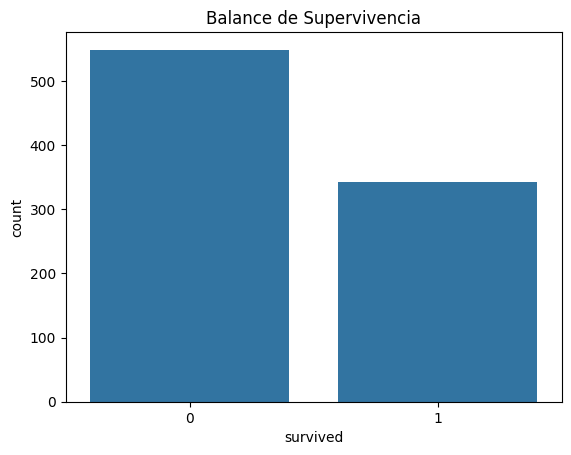

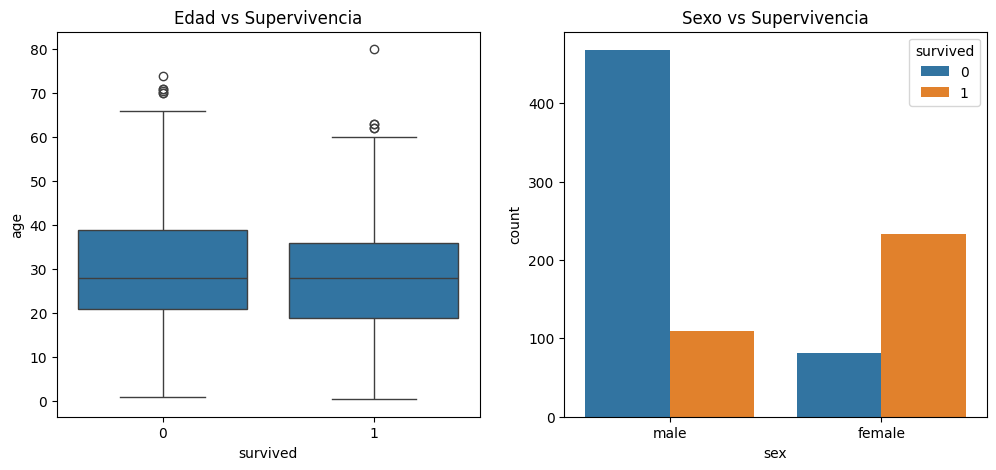

In [7]:
# Forma y detección de nulos
print(f"Forma de la tabla: {df.shape}")
print("\nValores nulos por columna:\n", df.isnull().sum())

# Balance de supervivencia
print("\nBalance de clases (Sobrevivió vs No sobrevivió):\n", df['survived'].value_counts(normalize=True))

# Gráfica de balance
sns.countplot(data=df, x='survived')
plt.title('Balance de Supervivencia')
plt.show()

# Distribuciones y relación con la supervivencia (Ejemplos)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x='survived', y='age', ax=axes[0])
axes[0].set_title('Edad vs Supervivencia')

sns.countplot(data=df, x='sex', hue='survived', ax=axes[1])
axes[1].set_title('Sexo vs Supervivencia')
plt.show()

## División de datos para entrenamiento (Triain/Test) y validación Cruzada 
Uso de Stratify

In [9]:
X = df.drop('survived', axis=1)
y = df['survived']

# División estratificada 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Validación cruzada estratificada sobre train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Creación de Pipeline

In [11]:
# Definir tipos de variables
vars_numericas = ['age', 'sibsp', 'parch', 'fare']
vars_categoricas = ['pclass', 'sex', 'embarked'] # pclass se trata como categórica para OneHot

# 1. Pipeline Numérico para el Árbol (Solo imputar nulos)
num_transformer_tree = SimpleImputer(strategy='median')

# 2. Pipeline Numérico para KNN (Imputar nulos + Estandarizar)
num_transformer_knn = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Pipeline Categórico (común para ambos)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Ensamblar los preprocesadores
preprocessor_tree = ColumnTransformer(transformers=[
    ('num', num_transformer_tree, vars_numericas),
    ('cat', cat_transformer, vars_categoricas)
])

preprocessor_knn = ColumnTransformer(transformers=[
    ('num', num_transformer_knn, vars_numericas),
    ('cat', cat_transformer, vars_categoricas)
])

## Árbol de decisión
Utilizando GridSearchCV

In [12]:
tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_tree),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Hiperparámetros a buscar
param_grid_tree = {
    'classifier__max_depth': [2, 3, 4, 5, 6, 7, 8],
    'classifier__min_samples_leaf': [1, 2, 5, 10]
}

grid_tree = GridSearchCV(tree_pipeline, param_grid_tree, cv=cv, scoring='accuracy', n_jobs=-1)
grid_tree.fit(X_train, y_train)

print(f"Mejor Árbol - Parámetros: {grid_tree.best_params_}")
print(f"Mejor Árbol - Accuracy CV: {grid_tree.best_score_:.4f}")

Mejor Árbol - Parámetros: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 1}
Mejor Árbol - Accuracy CV: 0.8174


## KNN 
Graficando Accuracy vs K

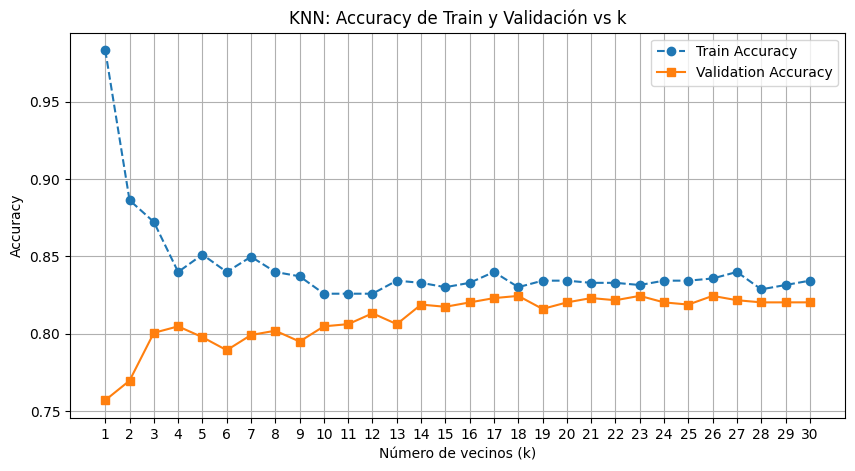

Mejor k encontrado: 23 con Accuracy CV de 0.8244


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['pclass','sex','age',...,'parch','fare','embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining column

In [13]:
k_values = list(range(1, 31))
train_scores = []
val_scores = []

for k in k_values:
    knn_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_knn),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])
    
    # Accuracy en entrenamiento directo
    knn_pipeline.fit(X_train, y_train)
    y_train_pred = knn_pipeline.predict(X_train)
    train_scores.append(accuracy_score(y_train, y_train_pred))
    
    # Accuracy en validación cruzada (media de las particiones)
    cv_score = cross_val_score(knn_pipeline, X_train, y_train, cv=cv, scoring='accuracy').mean()
    val_scores.append(cv_score)

# Gráfica
plt.figure(figsize=(10, 5))
plt.plot(k_values, train_scores, label='Train Accuracy', marker='o', linestyle='--')
plt.plot(k_values, val_scores, label='Validation Accuracy', marker='s')
plt.title('KNN: Accuracy de Train y Validación vs k')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.show()

# Seleccionar el mejor k basado en la validación
mejor_k = k_values[np.argmax(val_scores)]
mejor_score_knn = max(val_scores)
print(f"Mejor k encontrado: {mejor_k} con Accuracy CV de {mejor_score_knn:.4f}")

# Reentrenar KNN con el mejor k usando todo el train set
best_knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_knn),
    ('classifier', KNeighborsClassifier(n_neighbors=mejor_k))
])
best_knn_pipeline.fit(X_train, y_train)

## Evaluación final en Test y la comparación


--- Comparación de Modelos ---


,Modelo,Accuracy CV (Media),Accuracy Test
0,Árbol de Decisión,0.817433,0.787709
1,KNN,0.824446,0.787709
2,Baseline (Mayoritaria),N/A,0.614525


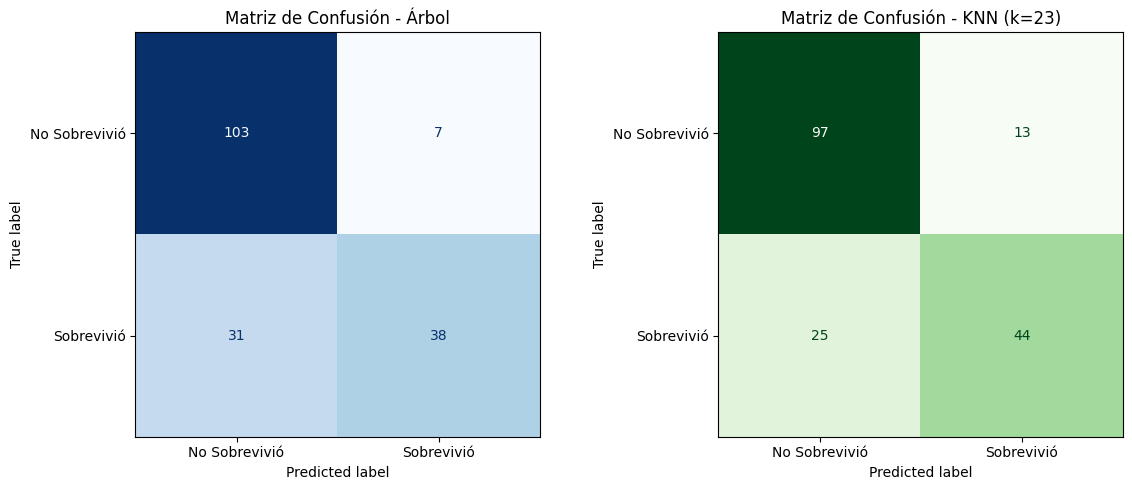

In [14]:
# Baseline: Predecir siempre la clase mayoritaria de train
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

# Predicciones en Test
y_test_pred_tree = grid_tree.predict(X_test)
y_test_pred_knn = best_knn_pipeline.predict(X_test)
y_test_pred_dummy = dummy.predict(X_test)

# Tabla de resultados
resultados = pd.DataFrame({
    'Modelo': ['Árbol de Decisión', 'KNN', 'Baseline (Mayoritaria)'],
    'Accuracy CV (Media)': [grid_tree.best_score_, mejor_score_knn, 'N/A'],
    'Accuracy Test': [
        accuracy_score(y_test, y_test_pred_tree),
        accuracy_score(y_test, y_test_pred_knn),
        accuracy_score(y_test, y_test_pred_dummy)
    ]
})
print("\n--- Comparación de Modelos ---")
display(resultados)

# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_tree = confusion_matrix(y_test, y_test_pred_tree)
disp_tree = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=['No Sobrevivió', 'Sobrevivió'])
disp_tree.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de Confusión - Árbol')

cm_knn = confusion_matrix(y_test, y_test_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['No Sobrevivió', 'Sobrevivió'])
disp_knn.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f'Matriz de Confusión - KNN (k={mejor_k})')

plt.tight_layout()
plt.show()